# 09 · BEV-lifter adapter (any LIFTERS entry → triplane) → triplane (TPV), step by step

**`TRIPLANE_LIFTERS["bev_adapter"]` → `lifting.triplane.BEVLifterTriplaneAdapter`**  ·  generic: wraps every entry of `lifting.lifters.LIFTERS`, including your own plug-ins

> Run any registered BEV lifter unchanged, then expand its BEV map into three planes with the learned BEVToTPV: xy from the map, xz / yz from pooled columns expanded along height.

This notebook shows, cell by cell, how the **BEV-lifter adapter (any LIFTERS entry → triplane)** lifting technique produces a
**tri-perspective view** (three orthogonal feature planes `xy` = BEV, `xz`, `yz`) instead of a single
bird's-eye-view map, *without changing a line of the existing BEV lifter* - the triplane module wraps it
(composition) and only adds what is needed to keep the height axis.

| § | what you will see |
|---|---|
| 1 | the idea, the animated step-by-step GIF and a detailed Mermaid diagram |
| 2 | every animation step as a still image |
| 3 | the shared toy scene (4 cameras, vehicles, pedestrians) |
| 4 | building the triplane lifter from the registry |
| 5 | **inside the lifter**: every intermediate tensor, with exact checks |
| 6 | the triplane contract, verified |
| 7 | end-to-end training on 3D semantic occupancy |
| 8 | the negative control: does it really use the cameras? |
| 9 | how to use it in your own code, recap, cheat sheet, exercises |

## 1. The idea

![BEV-lifter adapter (any LIFTERS entry → triplane) triplane lifting animation](../../assets/triplane/bev_adapter.gif)


The dedicated triplane lifters (notebooks 01-07) recover height **from the images**. Sometimes you just want TPV
outputs from a BEV lifter you already have - including one you registered yourself. `BEVLifterTriplaneAdapter` does:

1. `LIFTERS.build(base, ...)` - **any** registered BEV lifter, untouched, produces a BEV map `(B, C, X, Y)`;
2. `BEVToTPV` (existing module) turns it into planes:
   * `xy` = two `ConvNormAct` on the BEV map;
   * `xz` = BEV averaged over `y`, then a `1×1` conv expands every `x` column into `Z` height cells;
   * `yz` = BEV averaged over `x`, expanded the same way.

Height is **not** in a BEV map, so `xz` / `yz` are learned *guesses* from what is in each column (e.g. "a vehicle is
~1.6 m tall"). The adapter inherits `uses_geometry` from the wrapped lifter, and `resolve_kwargs` forwards the build
context (`feature_size`, `num_cameras`, `depth_bins`) to it - so `build_triplane_lifter("bev_adapter", ...,
base="mlp_view")` just works.

### Detailed diagram

Colours: <span style="color:#d48806">■ data</span> · <span style="color:#1f77b4">■ fixed geometry</span>
· <span style="color:#8e44ad">■ learned</span> · <span style="color:#2e8b57">■ reused from the existing BEV lifter</span>
· <span style="color:#c0392b">■ outputs</span>. (Mermaid renders in JupyterLab ≥ 4.1, VS Code and on GitHub;
the matplotlib version below renders everywhere.)

```mermaid
flowchart LR
  IMG["N camera images<br/>(B, N, 3, H, W)"]:::data --> ENC["ImageEncoder<br/>pyramid (B, N, C, H_l, W_l)"]:::learned
  CAM["Cameras<br/>K (B,N,3,3) · cam_to_ego (B,N,4,4)"]:::data
  subgraph CORE["ANY entry of LIFTERS (existing, unchanged)<br/>simple_bev · depth_warp · lift_splat · tiim · bevformer · tpvformer · alpamayo · mlp_view · your plug-in"]
    direction TB
    L["BaseLifter.forward"]:::reused
  end
  ENC --> L
  CAM --> L
  L --> B["BEV map (B, C, X, Y)"]:::reused
  subgraph B2T["BEVToTPV (existing)"]
    direction TB
    PXY["xy = two ConvNormAct on BEV"]:::learned
    PXZ["xz = mean over y → 1×1 conv expands each column to Z"]:::learned
    PYZ["yz = mean over x → 1×1 conv expands each column to Z"]:::learned
  end
  B --> PXY & PXZ & PYZ
  PXY & PXZ & PYZ --> TPV
  TPV["TPVPlanes<br/>xy (B,C,X,Y) · xz (B,C,X,Z) · yz (B,C,Y,Z)"]:::out
  TPV --> BEVH["TriplaneBEVHead<br/>f = xy + xz + yz → fold Z<br/>BEV (B, C, X, Y)"]:::learned
  TPV --> AGG["TPVAggregator<br/>voxel logits (B,K,X,Y,Z)<br/>+ point logits (B,K,P)"]:::learned
  classDef data fill:#fff7e6,stroke:#d48806,color:#222
  classDef geo fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef learned fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef reused fill:#eaf7ea,stroke:#2e8b57,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

### Shapes and equations


$$ B = \mathrm{Lifter}_\text{base}(F, \text{cams}) \in \mathbb{R}^{C \times X \times Y} $$

$$ xy = \mathrm{CNA}(\mathrm{CNA}(B)),\qquad xz[:, x, z] = \big(W_{xz}\, \tfrac{1}{Y}\textstyle\sum_y B[:, x, y]\big)_{z},\qquad
yz[:, y, z] = \big(W_{yz}\, \tfrac{1}{X}\textstyle\sum_x B[:, x, y]\big)_{z} $$

with $W \in \mathbb{R}^{(C\cdot Z) \times C}$ a `1×1` convolution - the inverse direction of `HeightCompressor`.

| tensor | shape |
|---|---|
| BEV map | `(B, C, X, Y)` |
| pooled columns | `(B, C, X)` and `(B, C, Y)` |
| planes | `xy (B,C,X,Y)`, `xz (B,C,X,Z)`, `yz (B,C,Y,Z)` |

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")

# tpv_kit lives next to this notebook; also works when Jupyter starts at the repo root.
for _p in (".", os.path.join("notebooks", "triplane")):
    if os.path.isdir(os.path.join(_p, "tpv_kit")):
        sys.path.insert(0, os.path.abspath(_p)); break

import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt

from lifting import BaseLifter
from lifting.encoders import SimpleConvEncoder
from lifting.lifters import LIFTERS
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_lifter, build_triplane_model, build_triplane_bev_model
from tpv_kit import (TriplaneScene, PlanePlotter, PipelineDiagram, StoryboardViewer,
                     TriplaneContractChecker, OccupancyExperiment, ExperimentResult)

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 100, "image.interpolation": "nearest"})
plotter = PlanePlotter()
print("torch", torch.__version__, "| triplane lifters:", TRIPLANE_LIFTERS.names())

torch 2.14.1 | triplane lifters: ['alpamayo', 'bev_adapter', 'bevformer', 'depth_warp', 'lift_splat', 'mlp_view', 'simple_bev', 'tiim', 'tpvformer']


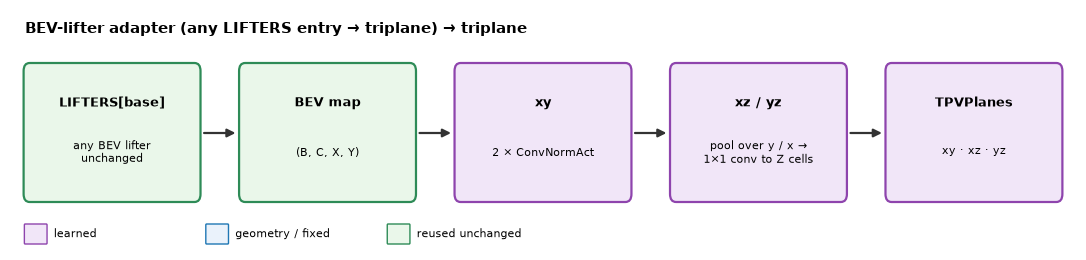

In [2]:
PipelineDiagram('BEV-lifter adapter (any LIFTERS entry → triplane) → triplane').extend([
    ('LIFTERS[base]', 'any BEV lifter\nunchanged', 'reused'),
    ('BEV map', '(B, C, X, Y)', 'reused'),
    ('xy', '2 × ConvNormAct', 'learned'),
    ('xz / yz', 'pool over y / x →\n1×1 conv to Z cells', 'learned'),
    ('TPVPlanes', 'xy · xz · yz', 'learned'),
]).show()

## 2. The animation, one still per step

The GIF above is rendered by `lifting.triplane.animation` (Pillow only, exact geometry on a toy scene:
4 cameras at the origin, a car, a pedestrian and a pole). `StoryboardViewer` re-renders the **final frame of every
step** so the whole sequence can be read at once. Regenerate all GIFs with `python scripts/make_triplane_gifs.py`.

step 1: Inputs
step 2: Any BEV lifter -> BEV map
step 3: Pool along y -> expand to z (xz)
step 4: Pool along x -> expand to z (yz)
step 5: Triplane output


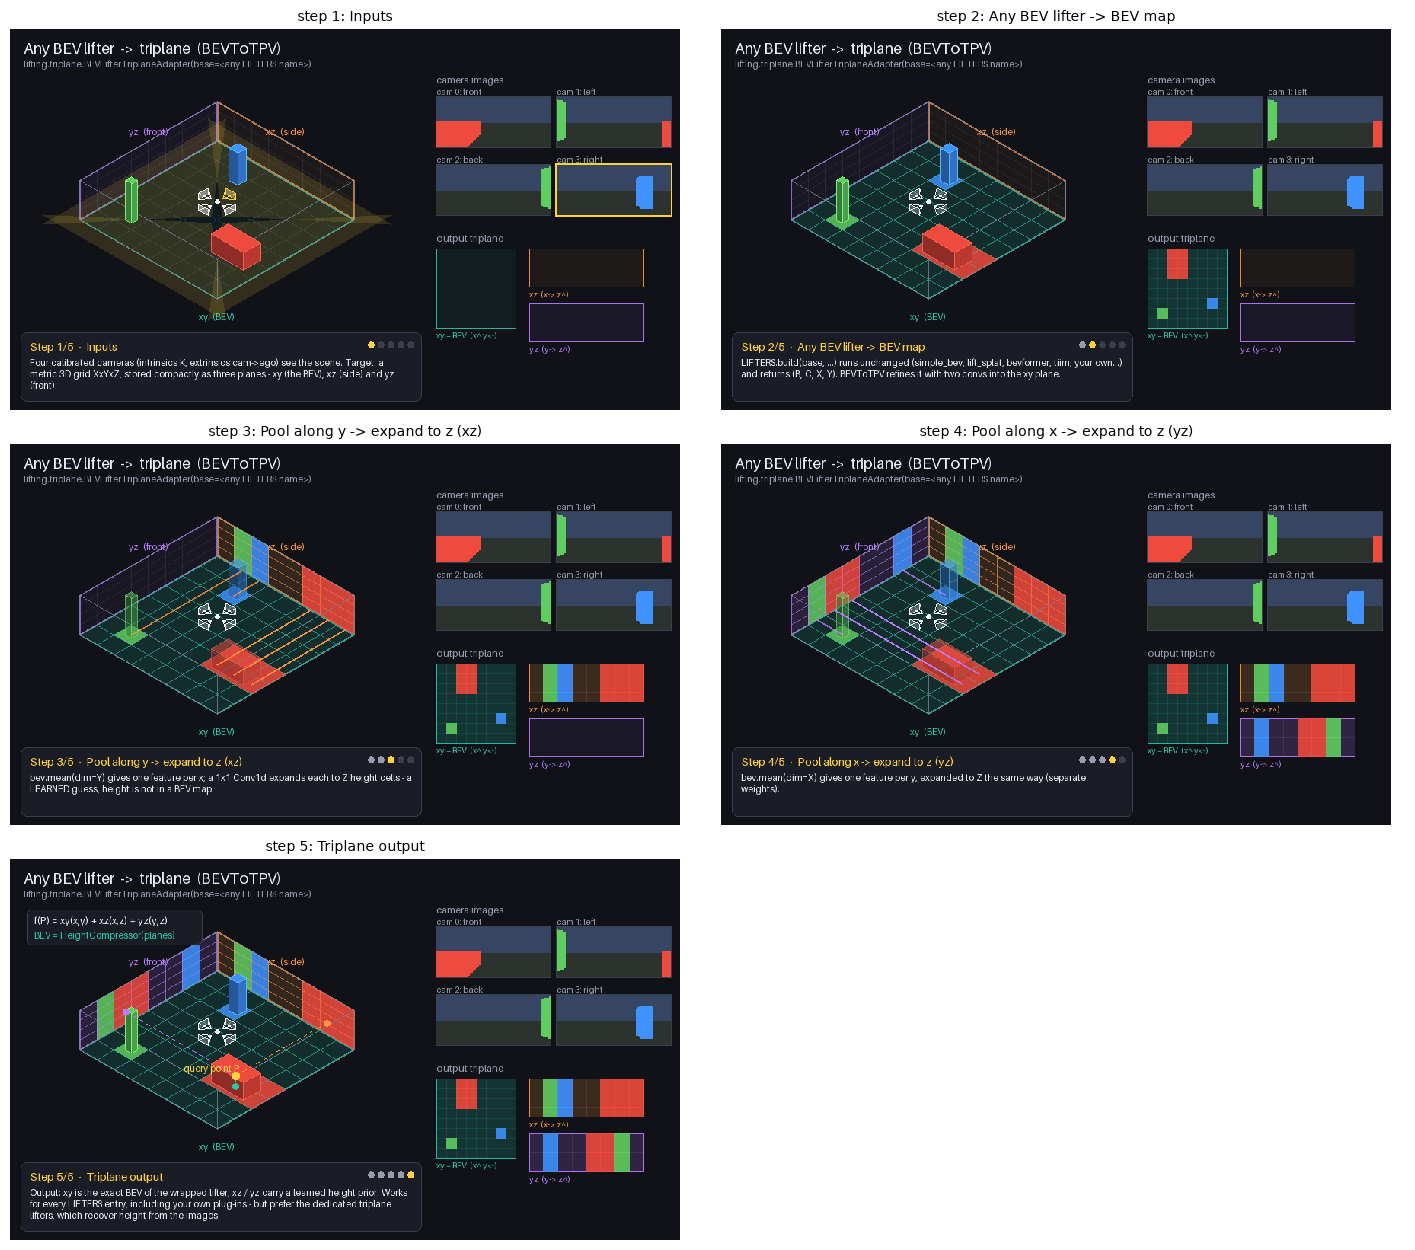

In [3]:
viewer = StoryboardViewer("bev_adapter")
for i, title in enumerate(viewer.step_titles(), 1):
    print(f"step {i}: {title}")
viewer.contact_sheet()

## 3. The scene

Every triplane notebook uses the same `TriplaneScene`: a `32 m × 32 m × 4 m` region cut into `16 × 16 × 4`
cells, four `48 × 96` cameras whose yaw is **randomly rotated per scene** (so no network can memorise where
"front" is - it must read the calibration), and procedurally placed vehicles (red) and pedestrians (blue).
The ground truth is a 3D occupancy grid `(B, X, Y, Z)`; collapsing it along each axis gives the three
**label planes** each triplane is supervised against.

grid      : x (-16.0, 16.0) y (-16.0, 16.0) z (-1.0, 3.0) m, resolution (16, 16, 4)
voxel     : (2.0, 2.0, 1.0) m
cameras   : 4 x (48, 96) px
scenes    : 128 train / 32 test (batch 4)
TPV cells : xy 256 + xz 64 + yz 64 = 384  (voxels: 1024)


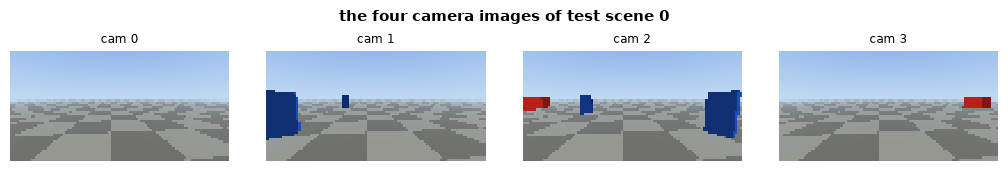

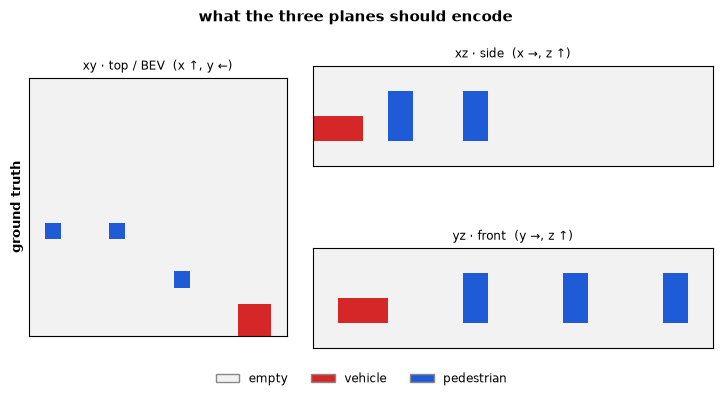

In [4]:
scene = TriplaneScene()
print(scene.describe())
batch = scene.sample
plotter.cameras(batch.images, title="the four camera images of test scene 0")
plotter.labels([("ground truth", scene.label_planes(batch.occupancy))], title="what the three planes should encode")

## 4. Build the triplane lifter

Two equivalent ways:

* `TRIPLANE_LIFTERS.build("bev_adapter", grid=..., in_channels=..., out_channels=...)` - the raw registry;
* `build_triplane_lifter("bev_adapter", grid, channels, image_size, num_cameras, encoder)` - also injects the
  context some lifters need (`feature_size`, `num_cameras`, `depth_bins`), exactly like `lifting.models.build_lifter`
  does for BEV lifters.

The image encoder turns `(B·N, 3, H, W)` images into a feature pyramid (strides 4 and 8 here); every lifter
consumes `(B, N, C, H_l, W_l)` per level.

In [5]:
C = 32
encoder = SimpleConvEncoder(out_channels=C, num_levels=2)
features = scene.encode(encoder, batch)
cameras = batch.cameras
print("feature pyramid:", [tuple(f.shape) for f in features])

lifter = build_triplane_lifter("bev_adapter", scene.grid, C, scene.image_size, scene.num_cameras, encoder, base="simple_bev")
print(type(lifter).__name__, "| is a BaseLifter too:", isinstance(lifter, BaseLifter))
print(f"parameters: {sum(p.numel() for p in lifter.parameters()):,}")
for name, child in lifter.named_children():
    n = sum(p.numel() for p in child.parameters())
    print(f"  .{name:<12s} {type(child).__name__:<28s} {n:>9,} params")

feature pyramid: [(4, 4, 32, 12, 24), (4, 4, 32, 6, 12)]
BEVLifterTriplaneAdapter | is a BaseLifter too: True
parameters: 103,232
  .bev_head     TriplaneBEVHead                 37,984 params
  .core         BilinearSamplingLifter          37,984 params
  .to_planes    BEVToTPV                        27,264 params


## 5. Inside the lifter, step by step

### 5.1 Every registered BEV lifter becomes a triplane lifter

Including a lifter defined **in this notebook** (an inverse-perspective-mapping lifter, as in
`examples/custom_lifter.py`): register it in `LIFTERS` and the adapter wraps it - no library change.

In [6]:
from collections.abc import Sequence
from lifting import Cameras, GridSpec
from lifting.layers import ConvNormAct
from lifting.ops import masked_camera_mean, sample_multi_camera

class NotebookGroundPlaneLifter(BaseLifter):
    """Inverse perspective mapping: every BEV cell reads only its ground point (z = 0)."""
    def __init__(self, grid: GridSpec, in_channels: int, out_channels: int) -> None:
        super().__init__(grid, in_channels, out_channels)
        self.out = ConvNormAct(in_channels, out_channels)
    def forward(self, features: Sequence[torch.Tensor], cameras: Cameras) -> torch.Tensor:
        feats = features[0]
        b, _, c = feats.shape[:3]
        ground = self.grid.voxel_centers(feats.device)[:, :, 0].clone()
        ground[..., 2] = 0.0
        uv, _, valid = cameras.project(ground.view(1, -1, 3).expand(b, -1, -1))
        bev = masked_camera_mean(sample_multi_camera(feats, cameras.normalize_uv(uv)), valid)
        return self.out(bev.view(b, c, *self.grid.bev_shape))

if "nb_ground_plane" not in LIFTERS:                  # re-running the cell must not re-register
    LIFTERS.register("nb_ground_plane")(NotebookGroundPlaneLifter)

for base in LIFTERS.names():
    extra = {"num_layers": 1} if base in {"bevformer", "tpvformer", "alpamayo"} else {}
    wrapped = build_triplane_lifter("bev_adapter", scene.grid, C, scene.image_size, scene.num_cameras, encoder,
                                    base=base, base_kwargs=extra)
    with torch.no_grad():
        p = wrapped.lift_planes(features, cameras)
    print(f"{base:16s} -> core {type(wrapped.core).__name__:24s} planes {[tuple(t.shape[1:]) for t in (p.xy, p.xz, p.yz)]}"
          f"  uses_geometry={wrapped.uses_geometry}")

alpamayo         -> core AlpamayoTriplaneLifter   planes [(32, 16, 16), (32, 16, 4), (32, 16, 4)]  uses_geometry=True
bevformer        -> core BEVFormerLifter          planes [(32, 16, 16), (32, 16, 4), (32, 16, 4)]  uses_geometry=True
depth_warp       -> core DepthWarpLifter          planes [(32, 16, 16), (32, 16, 4), (32, 16, 4)]  uses_geometry=True
lift_splat       -> core LiftSplatLifter          planes [(32, 16, 16), (32, 16, 4), (32, 16, 4)]  uses_geometry=True
mlp_view         -> core MLPViewLifter            planes [(32, 16, 16), (32, 16, 4), (32, 16, 4)]  uses_geometry=False
nb_ground_plane  -> core NotebookGroundPlaneLifter planes [(32, 16, 16), (32, 16, 4), (32, 16, 4)]  uses_geometry=True
simple_bev       -> core BilinearSamplingLifter   planes [(32, 16, 16), (32, 16, 4), (32, 16, 4)]  uses_geometry=True
tiim             -> core PolarRayLifter           planes [(32, 16, 16), (32, 16, 4), (32, 16, 4)]  uses_geometry=True
tpvformer        -> core TPVFormerLifter          plan

### 5.2 `BEVToTPV`: what the side planes can and cannot know

`xz` only sees the BEV map **averaged over `y`**. Shuffle the BEV map along `y` - objects move left/right, the column
averages do not - and `xz` does not change at all, while `xy` does. That is the information a BEV map loses, and why the
dedicated triplane lifters (which read height from the images) exist.

In [7]:
to_tpv = lifter.to_planes.eval()
bev = lifter.core(features, cameras).detach()
perm = torch.randperm(bev.shape[3])
with torch.no_grad():
    p1, p2 = to_tpv(bev), to_tpv(bev[..., perm])
print("xz unchanged after shuffling y:", torch.allclose(p1.xz, p2.xz, atol=1e-6))
print("xy unchanged after shuffling y:", torch.allclose(p1.xy, p2.xy, atol=1e-6))
print("column expander:", to_tpv.proj_xz[0], "->", f"C x Z = {to_tpv.out_channels} x {to_tpv.resolution[2]}")

xz unchanged after shuffling y: True
xy unchanged after shuffling y: False
column expander: Conv1d(32, 128, kernel_size=(1,), stride=(1,), bias=False) -> C x Z = 32 x 4


## 6. The triplane contract, verified

Every triplane lifter promises the same five properties (Liskov: it is still a `BaseLifter`, so it drops into
`BEVSegmentationModel`, the trainer and the verifier unchanged). `TriplaneContractChecker` runs them on real tensors.

PASS  plane shapes            xy(4, 32, 16, 16) xz(4, 32, 16, 4) yz(4, 32, 16, 4)
PASS  BEV = bev_head(planes)  BEV (4, 32, 16, 16), max |diff| = 0.0e+00
PASS  f = xy + xz + yz        voxel (8,8,2) max |diff| = 0.0e+00
PASS  reuses BEV lifter       core = BilinearSamplingLifter = LIFTERS['simple_bev']
PASS  gradients reach images  1/2 pyramid levels receive gradient


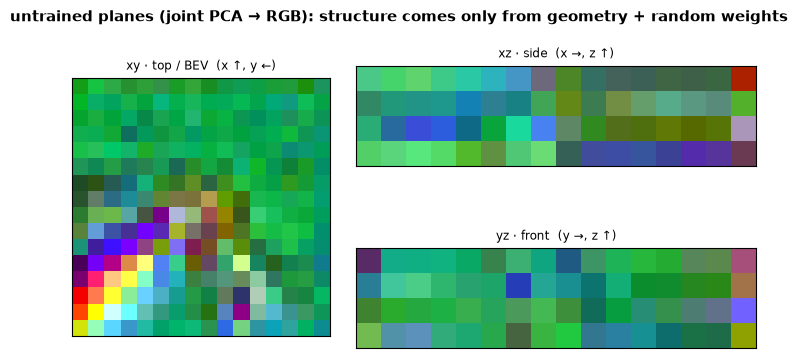

In [8]:
assert TriplaneContractChecker(lifter, features, cameras).run()
with torch.no_grad():
    planes = lifter.lift_planes(features, cameras)
plotter.features(planes, title="untrained planes (joint PCA → RGB): structure comes only from geometry + random weights")

## 7. Train end to end on 3D semantic occupancy

`build_triplane_model("bev_adapter", ...)` = encoder → **this triplane lifter** → `TPVAggregator` (an MLP on
`f(x,y,z) = xy + xz + yz`), plus one auxiliary classifier per plane. `OccupancyTask(aux_weight=0.5)` adds a
cross-entropy on each plane against the collapsed labels of §3. 150 AdamW steps on 128 scenes, CPU only.

lifter          params    time   before    after  corrupted   verdict
bev_adapter       240k    3.9s    0.013    0.381      0.031   uses geometry


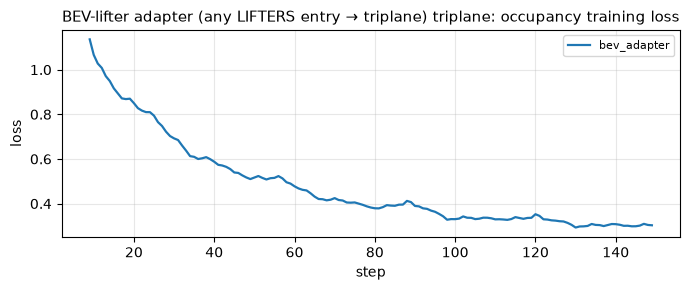

In [9]:
exp = OccupancyExperiment(scene, "bev_adapter", base="simple_bev")
result = exp.run(steps=150)
print(ExperimentResult.header()); print(result.row())
OccupancyExperiment.plot_losses([result], title="BEV-lifter adapter (any LIFTERS entry → triplane) triplane: occupancy training loss")

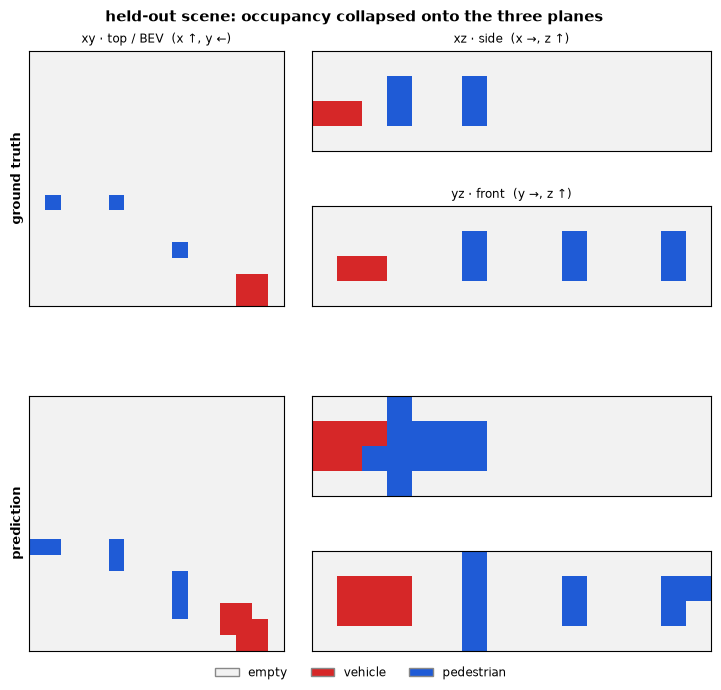

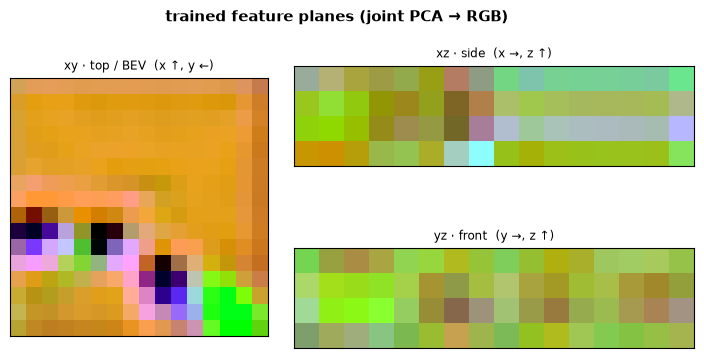

In [10]:
out = exp.predict()
pred = out["voxel_logits"].argmax(1)                       # (B, X, Y, Z) class ids
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("prediction", scene.label_planes(pred))],
               title="held-out scene: occupancy collapsed onto the three planes")
plotter.features(out["planes"], title="trained feature planes (joint PCA → RGB)")

### Adapter vs dedicated triplane lifter (same base)

On this synthetic world object height is almost a function of class (vehicles ~1.6 m, pedestrians ~1.8 m), so the
learned column expansion is a good guess and the adapter is competitive. On real scenes with varied heights,
overhangs and stacked objects the dedicated lifters, which read height from image rows, are the right choice.

In [11]:
result_dedicated = OccupancyExperiment(scene, "simple_bev").run(steps=150)
print(ExperimentResult.header()); print(result.row()); print(result_dedicated.row())

lifter          params    time   before    after  corrupted   verdict
bev_adapter       240k    3.9s    0.013    0.381      0.031   uses geometry
simple_bev        510k    4.2s    0.000    0.375      0.030   uses geometry


## 8. Negative control: does it really use the cameras?

Same images, same weights - but every camera's extrinsic is rotated by 90° about the vertical axis. A lifter that reads
pixels **through** the calibration now puts every object in the wrong place and its mIoU collapses; a geometry-free
lifter would not notice. (This is the triplane version of the repo's `lifting-verify` check.)

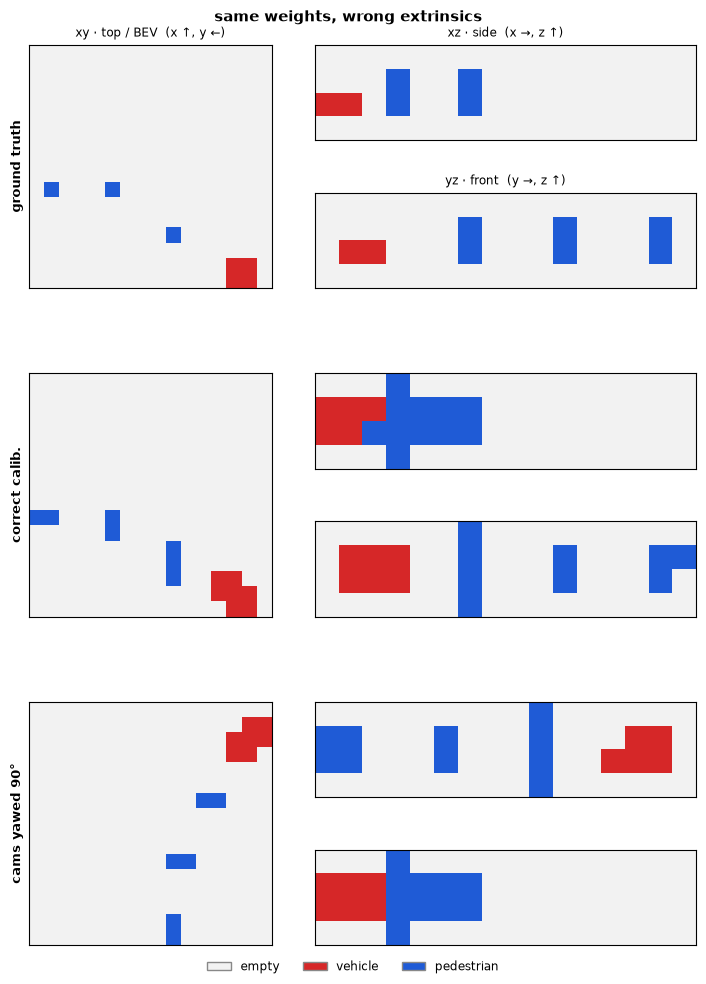

mIoU  correct calibration: 0.381   |   cameras yawed 90°: 0.031   ->  uses geometry ✅


In [12]:
corrupted = exp.predict(corrupted=True)["voxel_logits"].argmax(1)
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("correct calib.", scene.label_planes(pred)),
                ("cams yawed 90°", scene.label_planes(corrupted))],
               title="same weights, wrong extrinsics")
print(f"mIoU  correct calibration: {result.miou_after:.3f}   |   cameras yawed 90°: {result.miou_corrupted:.3f}"
      f"   ->  {'uses geometry ✅' if result.uses_geometry else 'does NOT use geometry'}")

## 9. Use it in your own code

```python
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_model, build_triplane_bev_model

# 1) just the lifter: features (B, N, C, H_l, W_l) per level + Cameras
lifter = TRIPLANE_LIFTERS.build("bev_adapter", grid=grid, in_channels=64, out_channels=64, base="simple_bev")
planes = lifter.lift_planes(features, cameras)   # TPVPlanes(xy, xz, yz)
bev    = lifter(features, cameras)               # (B, 64, X, Y) - drop-in BEV lifter

# 2) 3D semantic occupancy + point queries
model = build_triplane_model("bev_adapter", grid, num_classes=3, aux_heads=True, base="simple_bev")
out = model(images, cameras, points=lidar_xyz)   # planes, voxel_logits, point_logits, aux_logits

# 3) BEV segmentation read off the triplane (same API as lifting.build_bev_model)
bev_model = build_triplane_bev_model("bev_adapter", grid, num_classes=3, base="simple_bev")
```

In [13]:
bev_model = build_triplane_bev_model("bev_adapter", scene.grid, 3, scene.image_size, scene.num_cameras, channels=16, base="simple_bev")
with torch.no_grad():
    logits = bev_model(batch.images, batch.cameras)["logits"]
print("BEV segmentation logits read off the triplane:", tuple(logits.shape))

BEV segmentation logits read off the triplane: (4, 3, 16, 16)


## Recap


* `bev_adapter` turns **every** `LIFTERS` entry - built-in or your own - into a triplane lifter, unchanged.
* `xy` is the BEV map; `xz` / `yz` are learned height expansions of pooled columns (they cannot see where along the
  pooled axis something was).
* Prefer the dedicated triplane lifters when they exist; use the adapter for new / experimental BEV lifters.


**Cheat sheet**

| concept | file |
|---|---|
| adapter | `src/lifting/triplane/bev_lifter_adapter.py` |
| BEV → planes | `src/lifting/lifters/tpvformer/bev_to_tpv.py` |
| BEV lifter registry | `src/lifting/lifters/base.py` |
| custom lifter example | `examples/custom_lifter.py` |
| triplane contract | `src/lifting/triplane/base.py` |
| BEV read-off from planes | `src/lifting/triplane/triplane_bev_head.py` |
| occupancy model / factories | `src/lifting/triplane/triplane_occupancy_model.py`, `factory.py` |
| this animation | `src/lifting/triplane/animation/storyboards/bev_adapter_storyboard.py` |

**Exercises**

1. Wrap `nb_ground_plane` and train it. How does an IPM lifter do on the `xz` / `yz` planes?
2. Compare `bev_adapter(base="tpvformer")` with the native `tpvformer` triplane lifter (notebook 06).
3. Replace the mean pooling in `BEVToTPV` by max pooling (subclass) and compare.

Next: see `00_triplane_overview.ipynb` for all techniques side by side.